# Exceedance areas

Many fields come with a limit, an air pollutant above a health limit, a temperature above a heat
threshold, a flood depth above what a road can carry. Two questions follow. How much of the region lies
above the limit, which sizes the response. And how likely is each place to be above it, which decides
where to act, or where to place a new sensor or take another measurement. The first is about the whole
map at once, the second about one place at a time, so they need different readings of an ensemble. Here
we answer both on simulated fields whose truth we know, showing why neither the map of means nor the probability at each place answers the
first.

## Learning goals

- Why the area above a limit is a property of the whole field, read from the members as fields.
- How the members give the law of that area, a band that contains the true area.
- Why the area of the map of means understates it, while the mean probability gives no band.
- How the probability of exceeding the limit at each place maps the places to act on, with the least certain places for a new measurement.

*How much of a region lies above a limit, and how sure are we?*

## The idea

Let $\ell$ be the limit. The **exceedance area** is the share of the domain where the value exceeds it,

$$A(\ell) = \frac{1}{|D|} \int_D \mathbf 1\{Z(v) > \ell\}\, dv .$$

It depends on the values at every location together, so no collection of separate probabilities fixes
it. The **exceedance probability** at a location, $P(Z(v) > \ell)$, depends on that location's law alone.

An ensemble answers both. Each member is the reading of the field under one partition, a whole map, so
its exceeded share is one possible area, and the areas of all the members form the **law of the area**.
The share of members above the limit at one location is its exceedance probability. The book behind
Spatialize treats this as one of its situations, a pollutant under a legal limit, showing that the map of means understates the area, while averaging the probabilities gives the mean area and
nothing about its spread.

## Step by step

### A skewed field

The field is a Voronoi block-mark field on the unit square, 30 cells each with a lognormal value, a
skewed and positive variable like a concentration or a rainfall total, read at 350 locations. The limit
is the 80th percentile of the field, so about a fifth of the region lies above it.

limit 3.65, true exceedance area 0.193


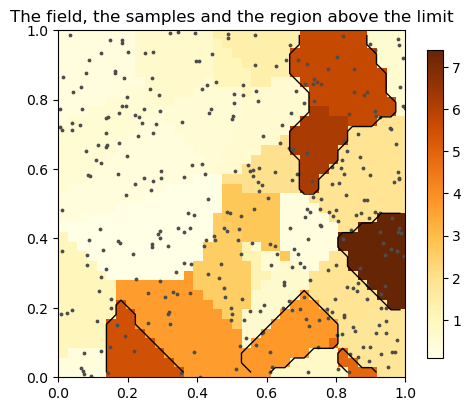

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
from spatialize.gs.ess import ess_sample
from spatialize.empirical import FittedModelFactory
import spatialize.gs.esi.scorefunction as sf
from spatialize.logging import singleton_null_callback as quiet

spatialize.session.set(empty_cells="coarsen", progress=False)

m = 36
grid = (np.arange(m) + 0.5) / m
xi = np.stack(np.meshgrid(grid, grid), -1).reshape(-1, 2)          # maps are [y, x]

def skewed_field(seed, n_cells=30, n_samples=350):
    rng = np.random.default_rng(seed)
    nuclei = rng.random((n_cells, 2))
    marks = rng.lognormal(0.0, 1.0, n_cells)
    value = lambda x: marks[np.argmin(((x[:, None, :] - nuclei[None]) ** 2).sum(-1), axis=1)]
    points = rng.random((n_samples, 2))
    return points, value(points), value(xi)

points, values, truth = skewed_field(0)
limit = np.quantile(truth, 0.8)
true_area = np.mean(truth > limit)
print(f"limit {limit:.2f}, true exceedance area {true_area:.3f}")

fig, ax = plt.subplots(figsize=(5.6, 5))
im = ax.imshow(truth.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="YlOrBr")
ax.contour(grid, grid, (truth > limit).reshape(m, m).astype(float), levels=[0.5], colors="black", linewidths=1)
ax.scatter(points[:, 0], points[:, 1], s=3, c="0.3")
ax.set_title("The field, the samples and the region above the limit")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

### Choosing the ensemble

The questions are about laws, so the ensemble is chosen by the CRPS, a score of the whole law, each
sample left out in turn, among the drawing decoders on Mondrian and Voronoi partitions.

In [2]:
rows, results = {}, {}
for p_process in ("mondrian", "voronoi"):
    for decoder, grid_kw in (("draw", {}), ("wdraw_idw", dict(exponent=[2.0])), ("wdraw_adaptiveidw", {})):
        knee = esi_pareto_hparams_search(points, values, local_interpolator=decoder, p_process=p_process,
                                         n_partitions=[100], alpha=[0.6, 0.7, 0.8, 0.9, 0.95], k="loo",
                                         scoring="crps", seed=0, **grid_kw).best_result(strategy="knee")
        rows[f"{p_process}, {decoder}"] = {"alpha": knee["alpha"], "leave-one-out CRPS": knee["decoder_error"],
                                           "options": {key: knee[key] for key in grid_kw}}
choice = pd.DataFrame(rows).T.sort_values("leave-one-out CRPS")
best_process, best_decoder = choice.index[0].split(", ")
recipe = dict(local_interpolator=best_decoder, p_process=best_process, alpha=choice.iloc[0]["alpha"],
              **choice.iloc[0]["options"])
print(f"chosen, {best_decoder} on {best_process} partitions at alpha {recipe['alpha']}")
choice[["alpha", "leave-one-out CRPS"]]

chosen, draw on voronoi partitions at alpha 0.9


,alpha,leave-one-out CRPS
"voronoi, draw",0.9,0.27193
"voronoi, wdraw_adaptiveidw",0.8,0.281934
"voronoi, wdraw_idw",0.9,0.285668
"mondrian, wdraw_adaptiveidw",0.95,0.293317
"mondrian, wdraw_idw",0.95,0.307507
"mondrian, draw",0.95,0.398662


### The law of the area

Each of 300 members is a map, so its share above the limit is one possible area. Three members, at the
5th, 50th and 95th percentiles of the areas, show how the exceeded region varies.

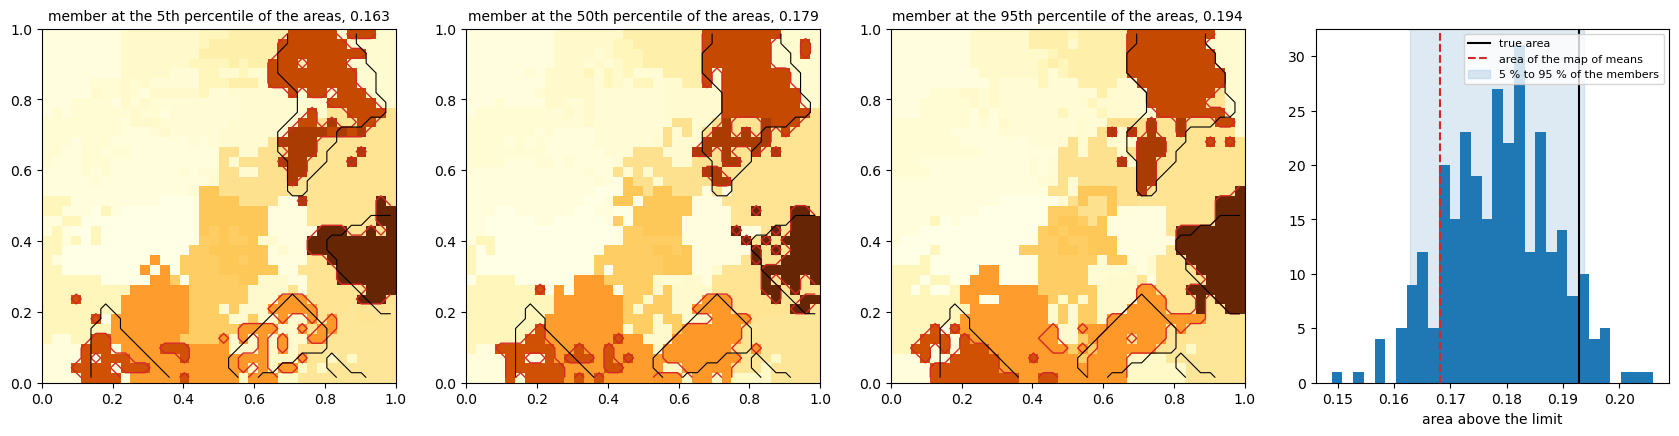

,area
true area,0.193
"members, 5 %",0.163
"members, median",0.179
"members, 95 %",0.194
map of means,0.168
mean exceedance probability,0.179


In [3]:
result = esi_nongriddata(points, values, xi, n_partitions=300, seed=0, **recipe)
members = result.esi_samples()
areas = (members > limit).mean(axis=0)
low, high = np.quantile(areas, [0.05, 0.95])
picks = [int(np.argsort(areas)[int(q * (len(areas) - 1))]) for q in (0.05, 0.5, 0.95)]
map_of_means_area = np.mean(members.mean(axis=1) > limit)
mean_probability = np.mean((members > limit).mean(axis=1))

fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for ax, t, q in zip(axes[:3], picks, ("5th", "50th", "95th")):
    ax.imshow(members[:, t].reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="YlOrBr", vmax=truth.max())
    ax.contour(grid, grid, (members[:, t] > limit).reshape(m, m).astype(float), levels=[0.5], colors="C3", linewidths=1)
    ax.contour(grid, grid, (truth > limit).reshape(m, m).astype(float), levels=[0.5], colors="black", linewidths=0.8)
    ax.set_title(f"member at the {q} percentile of the areas, {areas[t]:.3f}", fontsize=10)
axes[3].hist(areas, bins=30, color="C0")
axes[3].axvline(true_area, color="black", label="true area")
axes[3].axvline(map_of_means_area, color="C3", ls="--", label="area of the map of means")
axes[3].axvspan(low, high, color="C0", alpha=0.15, label="5 % to 95 % of the members")
axes[3].set_xlabel("area above the limit"); axes[3].legend(fontsize=8)
plt.show()
pd.Series({"true area": true_area, "members, 5 %": low, "members, median": np.median(areas), "members, 95 %": high,
           "map of means": map_of_means_area, "mean exceedance probability": mean_probability}).round(3).to_frame("area")

The members' areas run from 0.163 to 0.194 between their 5th and 95th percentiles, with the true
area, 0.193, just inside the upper end. The map of means gives 0.168, near the lower end of the band.
The mean exceedance probability gives 0.179, the mean of the members' areas, as it must, with no band
around it. The three members differ mostly at the edges of the patches, where a cell of one partition
straddles the limit.

### Where to measure next

The exceedance probability at each location, the share of members above the limit there, maps where
the limit is likely to be broken. The region where it exceeds one half is the ensemble's best guess of
the exceeded region. A probability near one half leaves the side of the limit most in doubt, so a new
sensor or measurement there settles the most.

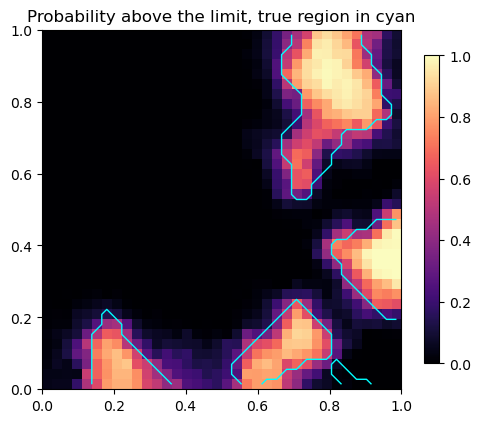

overlap of the region where the probability exceeds one half with the true region 0.78


In [4]:
probability = (members > limit).mean(axis=1)
guess, exceeded = probability > 0.5, truth > limit
fig, ax = plt.subplots(figsize=(5.8, 5))
im = ax.imshow(probability.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="magma", vmin=0, vmax=1)
ax.contour(grid, grid, exceeded.reshape(m, m).astype(float), levels=[0.5], colors="cyan", linewidths=1)
ax.set_title("Probability above the limit, true region in cyan")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
print(f"overlap of the region where the probability exceeds one half with the true region "
      f"{(guess & exceeded).sum() / (guess | exceeded).sum():.2f}")

The probability is close to one inside the large patches and fades over a margin of a few cells at
their edges, where the partitions disagree on the boundary. The region where it exceeds one half overlaps the true
region at 0.78, the shared area over the joint area. The small patch near (0.85, 0.05) barely shows,
since few samples fall in it. The margins of the patches, with that small patch, are where another
measurement would help most.

### Simulated fields

Spatialize can also simulate fields from the law at each location (`ess_sample`), drawing every location
independently from its own law. Such fields serve the probability at each place, a reading of one
location at a time. The area is a reading of all the locations together, which independent draws do not
keep.

In [5]:
simulations = np.asarray(ess_sample(result, n_sims=300, fitted_model_factory=FittedModelFactory(seed=0), callback=quiet).scenarios).reshape(len(xi), -1)
simulated_areas = (simulations > limit).mean(axis=0)
pd.Series({"true area": true_area, "simulated fields, mean area": simulated_areas.mean(),
           "simulated fields, 5 %": np.quantile(simulated_areas, 0.05),
           "simulated fields, 95 %": np.quantile(simulated_areas, 0.95),
           "members, 5 %": low, "members, 95 %": high}).round(3).to_frame("area")

,area
true area,0.193
"simulated fields, mean area",0.193
"simulated fields, 5 %",0.180
"simulated fields, 95 %",0.205
"members, 5 %",0.163
"members, 95 %",0.194


The simulated fields centre on 0.193 with a band from 0.180 to 0.205, four fifths as wide as the
members'. Here it contains the true area too, but its width counts only the noise of drawing 1 296
locations one by one. A finer grid narrows it further, while the uncertainty of the area stays the
same.

### Twenty fields

One field could flatter the band. The same recipe on twenty fields, each with its own granularity at
the knee, counts how often the band of the members contains the true area.

In [6]:
rows = []
for seed in range(20):
    p, v, t = skewed_field(seed)
    lim = np.quantile(t, 0.8)
    a = esi_pareto_hparams_search(p, v, local_interpolator=best_decoder, p_process=best_process, n_partitions=[100],
                                  alpha=[0.6, 0.7, 0.8, 0.9, 0.95], k="loo", scoring="crps", seed=0,
                                  **{key: [val] for key, val in choice.iloc[0]["options"].items()}).best_result(strategy="knee")["alpha"]
    mem = esi_nongriddata(p, v, xi, n_partitions=300, seed=0, **dict(recipe, alpha=a)).esi_samples()
    ar = (mem > lim).mean(axis=0)
    lo, hi = np.quantile(ar, [0.05, 0.95])
    rows.append({"true area": np.mean(t > lim), "band contains it": lo <= np.mean(t > lim) <= hi,
                 "median of the members": np.median(ar), "map of means": np.mean(mem.mean(axis=1) > lim)})
twenty = pd.DataFrame(rows)
pd.Series({"fields whose band contains the true area": twenty["band contains it"].mean(),
           "mean true area": twenty["true area"].mean(),
           "mean median of the members": twenty["median of the members"].mean(),
           "mean area of the map of means": twenty["map of means"].mean(),
           "fields where the map of means is below the truth": np.mean(twenty["map of means"] < twenty["true area"])}).round(3).to_frame()

,0
fields whose band contains the true area,0.850
mean true area,0.179
mean median of the members,0.173
mean area of the map of means,0.170
fields where the map of means is below the truth,0.650


Over twenty fields the band contains the true area in 17, 85 % against a nominal 90 %. On average the
members' median lies a little below the truth, 0.173 against 0.179. The map of means lies lower still,
at 0.170, below the truth in 13 of the 20 fields.

## Pitfalls

- **The area of the map of means.** Averaging pulls a location whose law reaches above the limit below it,
  so the map of means tends to understate the area on a skewed field. Read the area from the members.
- **The mean probability as the answer.** Averaging the exceedance probabilities over the region gives the
  mean area exactly, and nothing about its spread. The band comes from the members alone.
- **Simulated fields for the area.** They draw each location on its own, so their areas cluster too
  tightly. Use them for the probability at each place, not for the area.
- **An ensemble chosen for its map.** The area and the probabilities are readings of the law, so choose
  the ensemble by a score of laws, the CRPS, as here.
- **A band read as a point coverage.** The band's 90 % holds over many fields, not for this one. Over
  twenty fields it contains the true area in most of them, not all.

## Try it yourself

1. Lower the limit to the median of the field and compare the band with the map of means.
2. Draw the same field with 150 samples and watch the band widen.
3. Read the area above the limit within a sub-region, such as the left half of the region.

## Next

- *Rain, an atom at zero*, for the probability of a dry day.
- *Summaries over regions*, for the share above every threshold at once.
- *The probabilistic decoders*, for the drawing decoders.
- The documentation's [Ensemble simulation](https://spatialize.readthedocs.io/en/latest/reference/ess.html)
  (reference).